In [ ]:
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
DATA_PATH = "/content/drive/MyDrive/income.csv"
df = pd.read_csv(
    DATA_PATH
)
df.head()

Mounted at /content/drive


,Age,Income($)
0,19,15000
1,21,16000
2,20,17000
3,23,18000
4,22,19000


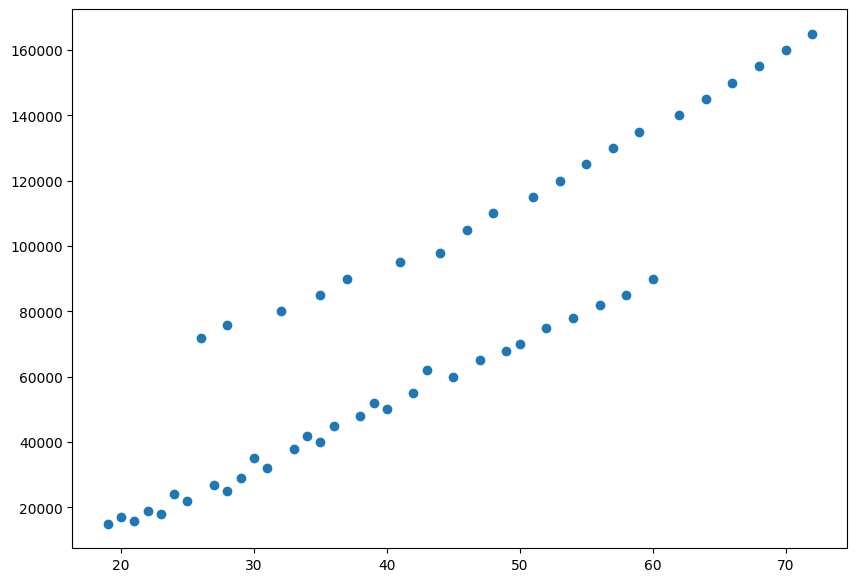

In [ ]:
plt.figure(figsize=(10,7))
plt.scatter(df["Age"],df["Income($)"])

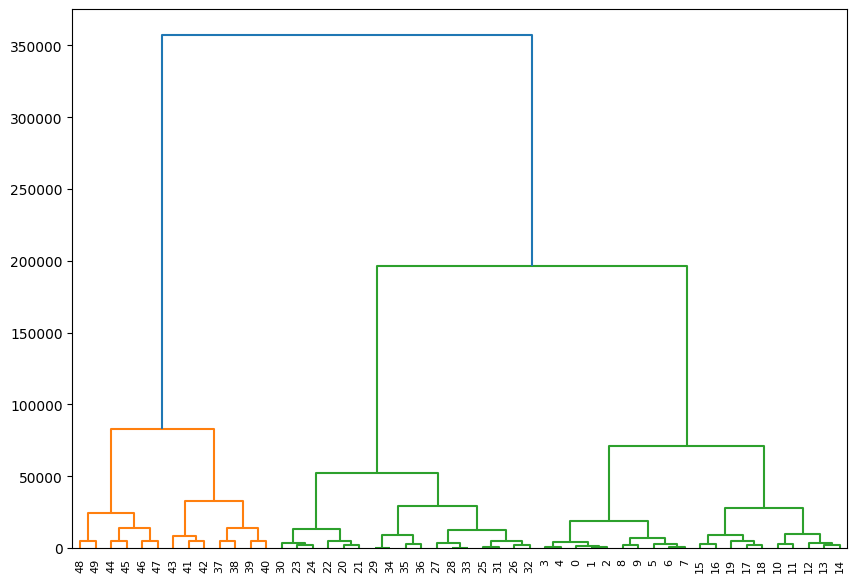

In [ ]:
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(10,7))
dendrogram = sch.dendrogram(sch.linkage(df,method="ward"))

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
import numpy as np
#import pandas as pd
scaler = StandardScaler()
data = pd.read_csv(DATA_PATH)
scaled_data = scaler.fit_transform(data)
scaled_data


array([[-1.62131809, -1.38381057],
       [-1.48321604, -1.36063116],
       [-1.55226706, -1.33745175],
       [-1.34511399, -1.31427235],
       [-1.41416501, -1.29109294],
       [-1.20701193, -1.22155472],
       [-1.27606296, -1.17519591],
       [-0.99985886, -1.1520165 ],
       [-1.06890988, -1.10565769],
       [-0.93080783, -1.05929888],
       [-0.79270578, -0.98976066],
       [-0.8617568 , -0.92022244],
       [-0.65460373, -0.85068422],
       [-0.51650167, -0.8043254 ],
       [-0.5855527 , -0.75796659],
       [-0.44745065, -0.68842837],
       [-0.3093486 , -0.61889015],
       [-0.17124654, -0.57253134],
       [-0.24029757, -0.52617253],
       [-0.03314449, -0.45663431],
       [ 0.17400859, -0.34073728],
       [ 0.03590653, -0.29437846],
       [ 0.31211064, -0.22484024],
       [ 0.45021269, -0.15530202],
       [ 0.51926372, -0.10894321],
       [ 0.65736577,  0.00695382],
       [ 0.79546782,  0.07649204],
       [ 0.93356987,  0.16920967],
       [ 1.07167192,

In [ ]:
model = AgglomerativeClustering(n_clusters=3,metric='euclidean',linkage='ward')
model.fit(data)

AgglomerativeClustering(n_clusters=3)

In [ ]:
x = model.fit_predict(scaled_data)
x

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1])

In [ ]:
data['predicted'] = x

In [ ]:
data1 = data[data['predicted']==0].copy()
data2 = data[data['predicted']==1].copy()
data3 = data[data['predicted']==2].copy()


/tmp/ipykernel_2934/825406259.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


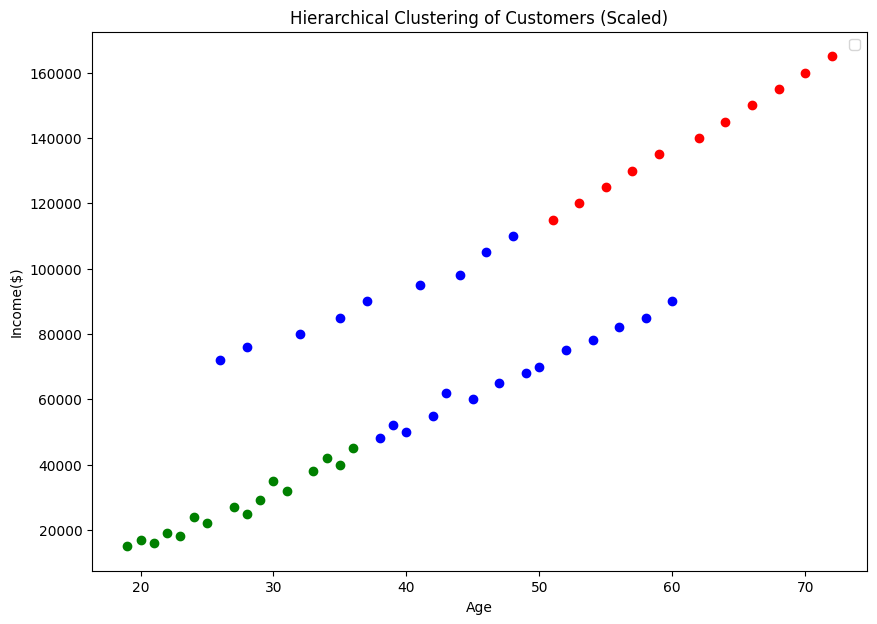

In [ ]:
#x = data.values
plt.figure(figsize=(10, 7))
# Cluster 0
#plt.scatter(x[pred == 0, 0], x[pred == 0, 1], c='red', label='Cluster 1')
# Cluster 1
#plt.scatter(x[pred == 1, 0], x[pred == 1, 1], c='blue', label='Cluster 2')
plt.scatter(data1['Age'],data1['Income($)'],color='blue')
plt.scatter(data2['Age'],data2['Income($)'],color='red')
plt.scatter(data3['Age'],data3['Income($)'],color='green')

plt.title('Hierarchical Clustering of Customers (Scaled)')
plt.xlabel("Age")
plt.ylabel("Income($)")
plt.legend()
plt.show()